# Sección 1: Carga del dataset

### ¿Qué es un DataFrame?

Una de las estructuras fundamentales de pandas es el **DataFrame**, que puede entenderse como una tabla con etiquetas (filas y columnas), muy similar a una hoja de cálculo de Excel, una tabla SQL o una tabla en R. Los **DataFrames** permiten representar datos heterogéneos, es decir, con columnas de distintos tipos (números, texto, booleanos, fechas, etc.).

### ¿Qué es un CSV?

Los archivos `.csv` (Comma-Separated Values) son uno de los formatos más comunes para el intercambio de datos tabulares. En estos archivos, cada fila representa una observación y cada columna un atributo, y están separados por comas (o en algunos países, por punto y coma o tabulaciones).


### Cargando datos con `pd.read_csv`

`pd.read_csv()` es una de las funciones más versátiles de pandas. Acepta muchísimos parámetros opcionales como:

- `sep`: para cambiar el separador (por defecto `,`)
- `header`: para indicar si hay fila de encabezado
- `na_values`: para definir valores que deben ser tratados como faltantes
- `dtype`: para forzar tipos de datos
- `usecols`: para cargar sólo ciertas columnas


In [ ]:
import pandas as pd
import os

# El dataset canónico se baja del Drive de la cátedra la primera vez que se corre el notebook
CANONICO = "fifa_canonico_2026-07-23.csv"
ID_DRIVE = "1cF30_fSvxNKpK5-AKJlzUqLHZTTUf0ls"

if not os.path.exists(CANONICO):
    !gdown $ID_DRIVE -O $CANONICO

# Leemos el archivo CSV y nos quedamos con los jugadores de la liga argentina
df = pd.read_csv(CANONICO, low_memory=False).query("league_country == 'Argentina'").reset_index(drop=True)

Downloading...
From: https://drive.google.com/uc?id=1cF30_fSvxNKpK5-AKJlzUqLHZTTUf0ls
To: /content/fifa_canonico_2026-07-23.csv
100% 9.56M/9.56M [00:00<00:00, 63.2MB/s]


In [ ]:
df.describe()

,player_id,nationality_id,fifa_version,fifa_update,league_id,club_team_id,club_jersey_number,club_contract_valid_until_year,age,height_cm,...,mentality_composure,defending_marking_awareness,defending_standing_tackle,defending_sliding_tackle,goalkeeping_diving,goalkeeping_handling,goalkeeping_kicking,goalkeeping_positioning,goalkeeping_reflexes,playstyles_count
count,884.000000,884.000000,884.0,884.0,884.0,884.000000,884.000000,884.000000,884.000000,884.000000,...,884.000000,884.000000,884.000000,884.000000,884.000000,884.000000,884.000000,884.000000,884.000000,884.000000
mean,196850.400452,53.625566,26.0,46.0,353.0,97158.497738,21.961538,2026.963801,25.363122,179.159502,...,58.795249,47.678733,49.994344,48.583710,15.290724,15.142534,15.114253,15.299774,15.391403,0.714932
std,79767.116800,10.965253,0.0,0.0,0.0,35485.976805,16.504047,1.213757,5.024114,6.642677,...,11.608367,19.745744,20.701759,20.350018,16.885675,16.296448,15.941976,16.637755,17.083320,1.230125
min,69957.000000,3.000000,26.0,46.0,353.0,1013.000000,1.000000,2026.000000,16.000000,156.000000,...,21.000000,5.000000,9.000000,7.000000,5.000000,5.000000,5.000000,5.000000,5.000000,0.000000
25%,83315.750000,52.000000,26.0,46.0,353.0,110093.000000,10.000000,2026.000000,21.000000,175.000000,...,51.000000,31.000000,31.000000,28.750000,8.000000,8.000000,8.000000,8.000000,8.000000,0.000000
50%,233160.500000,52.000000,26.0,46.0,353.0,111020.000000,20.000000,2026.000000,25.000000,179.000000,...,60.000000,53.000000,58.000000,57.000000,10.000000,10.000000,11.000000,10.000000,11.000000,0.000000
75%,260271.750000,52.000000,26.0,46.0,353.0,111715.000000,30.000000,2028.000000,29.000000,184.000000,...,67.250000,65.000000,68.000000,66.000000,13.000000,14.000000,13.000000,14.000000,13.000000,1.000000
max,279934.000000,186.000000,26.0,46.0,353.0,115472.000000,99.000000,2030.000000,40.000000,198.000000,...,86.000000,79.000000,78.000000,77.000000,79.000000,75.000000,74.000000,80.000000,79.000000,7.000000


### Verificación rápida del contenido

Una vez cargado el DataFrame, es fundamental inspeccionar visualmente las primeras filas usando `df.head()`.

Esto nos permite:

- Confirmar que los encabezados fueron leídos correctamente
- Ver si los valores tienen un formato esperado
- Detectar posibles problemas (decimales con coma, codificación incorrecta, valores faltantes, etc.)


In [ ]:
# Visualizamos las primeras filas del dataset
df.head()

,player_id,short_name,long_name,player_url,nationality_id,nationality_name,fifa_version,fifa_update,fifa_update_date,league_id,...,defending_sliding_tackle,goalkeeping_diving,goalkeeping_handling,goalkeeping_kicking,goalkeeping_positioning,goalkeeping_reflexes,player_traits,playstyles_count,acceleration_type,player_face_url
0,183898,Á. Di María,Ángel Di María,https://sofifa.com/player/183898/angel-di-mari...,52,Argentina,26,46,2026-07-23,353,...,39,10,7,11,12,11,"Finesse Shot, Chip Shot, Incisive Pass, Long B...",7,Controlled explosive,https://cdn.sofifa.net/players/183/898/26_120.png
1,207439,L. Paredes,Leandro Paredes,https://sofifa.com/player/207439/leandro-pared...,52,Argentina,26,46,2026-07-23,353,...,75,9,14,6,9,10,"Long Ball Pass, Tiki Taka",2,Controlled lengthy,https://cdn.sofifa.net/players/207/439/26_120.png
2,215270,L. Zelarayán,Lucas Zelarayán,https://sofifa.com/player/215270/lucas-zelaray...,3,Armenia,26,46,2026-07-23,353,...,35,8,9,11,6,10,"Dead Ball, Gamechanger, Incisive Pass, Whipped...",6,Controlled explosive,https://cdn.sofifa.net/players/215/270/26_120.png
3,182494,F. Muslera,Fernando Muslera,https://sofifa.com/player/182494/fernando-musl...,60,Uruguay,26,46,2026-07-23,353,...,21,79,74,69,80,79,"Long Ball Pass, Far Throw, Cross Claimer, Rush...",5,Controlled lengthy,https://cdn.sofifa.net/players/182/494/26_120.png
4,253242,A. Martínez,Adrián Martínez,https://sofifa.com/player/253242/adrian-martin...,52,Argentina,26,46,2026-07-23,353,...,33,13,11,10,16,14,"Chip Shot, Precision Header, Low Driven Shot, ...",4,Controlled explosive,https://cdn.sofifa.net/players/253/242/26_120.png


In [ ]:
# Dimensiones del DataFrame
df.shape

(884, 90)

In [ ]:
# Nombres de columnas
df.columns

Index(['player_id', 'short_name', 'long_name', 'player_url', 'nationality_id',
       'nationality_name', 'fifa_version', 'fifa_update', 'fifa_update_date',
       'league_id', 'league_name', 'league_country', 'club_team_id',
       'club_name', 'club_position', 'club_jersey_number', 'club_joined_date',
       'club_contract_valid_until_year', 'club_loan_end_date', 'age',
       'height_cm', 'weight_kg', 'preferred_foot', 'weak_foot', 'skill_moves',
       'international_reputation', 'body_type', 'real_face', 'overall',
       'potential', 'growth', 'best_overall', 'player_positions',
       'best_position', 'value_eur', 'wage_eur', 'release_clause_eur', 'pace',
       'shooting', 'passing', 'dribbling', 'defending', 'physic',
       'total_attacking', 'total_skill', 'total_movement', 'total_power',
       'total_mentality', 'total_defending', 'total_goalkeeping',
       'total_stats', 'base_stats', 'attacking_crossing',
       'attacking_finishing', 'attacking_heading_accuracy',
     

In [ ]:
# Tipos de datos por columna
df.dtypes

,0
player_id,int64
short_name,object
long_name,object
player_url,object
nationality_id,int64
...,...
goalkeeping_reflexes,int64
player_traits,object
playstyles_count,int64
acceleration_type,object


## Sección 1.1: Índices y nombres de columna

### ¿Qué es el índice de un DataFrame?

En pandas, cada `DataFrame` posee un **índice de filas** (accesible con `df.index`) que actúa como una etiqueta para identificar cada observación (fila). Por defecto, cuando se lee un archivo CSV, pandas asigna un `RangeIndex` con valores enteros consecutivos (0, 1, 2, ...). Sin embargo, este índice puede modificarse y personalizarse.

> 📌 Según *Python for Data Analysis* (Wes McKinney):  
> *"The index objects themselves are immutable and hold the axis labels and other metadata."*

El índice es clave para:
- Identificar filas de forma explícita
- Realizar alineación de datos
- Acceder y seleccionar datos de forma más expresiva
- Reindexar o reorganizar el contenido

### ¿Y los nombres de columna?

Los nombres de columnas (`df.columns`) también están representados internamente como un objeto `Index`. Sin embargo, su función principal es **etiquetar atributos o variables**, no observaciones. Aunque `df.columns` se comporta como un `Index`, no se lo considera el "índice" del DataFrame en el sentido principal.

### Acceso a los ejes del DataFrame

- `df.index` → índice de las filas (eje 0)
- `df.columns` → nombres de columnas (eje 1)

Ambos son objetos de tipo `pandas.Index`.

---

### Ejemplos con el dataset de jugadores

Supongamos que queremos:

1. Ver el índice actual del DataFrame
2. Usar la columna `"long_name"` como índice (porque cada jugador tiene un nombre completo)
3. Resetear el índice a su forma numérica original
4. Explorar los nombres de columnas y estandarizarlos


In [ ]:
# Índice actual: es un RangeIndex con enteros
df.index

RangeIndex(start=0, stop=884, step=1)

In [ ]:
# Nombres de columnas como objeto Index
df.columns

Index(['player_id', 'short_name', 'long_name', 'player_url', 'nationality_id',
       'nationality_name', 'fifa_version', 'fifa_update', 'fifa_update_date',
       'league_id', 'league_name', 'league_country', 'club_team_id',
       'club_name', 'club_position', 'club_jersey_number', 'club_joined_date',
       'club_contract_valid_until_year', 'club_loan_end_date', 'age',
       'height_cm', 'weight_kg', 'preferred_foot', 'weak_foot', 'skill_moves',
       'international_reputation', 'body_type', 'real_face', 'overall',
       'potential', 'growth', 'best_overall', 'player_positions',
       'best_position', 'value_eur', 'wage_eur', 'release_clause_eur', 'pace',
       'shooting', 'passing', 'dribbling', 'defending', 'physic',
       'total_attacking', 'total_skill', 'total_movement', 'total_power',
       'total_mentality', 'total_defending', 'total_goalkeeping',
       'total_stats', 'base_stats', 'attacking_crossing',
       'attacking_finishing', 'attacking_heading_accuracy',
     

In [ ]:
# Establecemos la columna 'long_name' como índice
df_named = df.set_index("long_name")
df_named

,player_id,short_name,player_url,nationality_id,nationality_name,fifa_version,fifa_update,fifa_update_date,league_id,league_name,...,defending_sliding_tackle,goalkeeping_diving,goalkeeping_handling,goalkeeping_kicking,goalkeeping_positioning,goalkeeping_reflexes,player_traits,playstyles_count,acceleration_type,player_face_url
long_name,,,,,,,,,,,,,,,,,,,,,
Ángel Di María,183898,Á. Di María,https://sofifa.com/player/183898/angel-di-mari...,52,Argentina,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,39,10,7,11,12,11,"Finesse Shot, Chip Shot, Incisive Pass, Long B...",7,Controlled explosive,https://cdn.sofifa.net/players/183/898/26_120.png
Leandro Paredes,207439,L. Paredes,https://sofifa.com/player/207439/leandro-pared...,52,Argentina,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,75,9,14,6,9,10,"Long Ball Pass, Tiki Taka",2,Controlled lengthy,https://cdn.sofifa.net/players/207/439/26_120.png
Lucas Zelarayán,215270,L. Zelarayán,https://sofifa.com/player/215270/lucas-zelaray...,3,Armenia,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,35,8,9,11,6,10,"Dead Ball, Gamechanger, Incisive Pass, Whipped...",6,Controlled explosive,https://cdn.sofifa.net/players/215/270/26_120.png
Fernando Muslera,182494,F. Muslera,https://sofifa.com/player/182494/fernando-musl...,60,Uruguay,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,21,79,74,69,80,79,"Long Ball Pass, Far Throw, Cross Claimer, Rush...",5,Controlled lengthy,https://cdn.sofifa.net/players/182/494/26_120.png
Adrián Martínez,253242,A. Martínez,https://sofifa.com/player/253242/adrian-martin...,52,Argentina,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,33,13,11,10,16,14,"Chip Shot, Precision Header, Low Driven Shot, ...",4,Controlled explosive,https://cdn.sofifa.net/players/253/242/26_120.png
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Emiliano Chiavassa,78171,E. Chiavassa,https://sofifa.com/player/78171/emiliano-chiav...,52,Argentina,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,24,10,6,15,5,13,NaN,0,Controlled,https://cdn.sofifa.net/players/078/171/26_120.png
Luca Feler,84092,L. Feler,https://sofifa.com/player/84092/luca-feler/260...,52,Argentina,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,47,11,14,6,8,10,NaN,0,Controlled,https://cdn.sofifa.net/players/084/092/26_120.png
Walter Núñez,83358,W. Núñez,https://sofifa.com/player/83358/walter-nunez/2...,52,Argentina,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,46,14,9,14,11,13,NaN,0,Controlled,https://cdn.sofifa.net/players/083/358/26_120.png


In [ ]:
# Ahora podemos acceder por nombre directamente
di_maria = df_named.loc["Ángel Di María"]
di_maria

,Ángel Di María
player_id,183898
short_name,Á. Di María
player_url,https://sofifa.com/player/183898/angel-di-mari...
nationality_id,52
nationality_name,Argentina
...,...
goalkeeping_reflexes,11
player_traits,"Finesse Shot, Chip Shot, Incisive Pass, Long B..."
playstyles_count,7
acceleration_type,Controlled explosive


In [ ]:
df_named.loc[["Ángel Di María"]]   # Devuelve un DataFrame de 1 fila

,player_id,short_name,player_url,nationality_id,nationality_name,fifa_version,fifa_update,fifa_update_date,league_id,league_name,...,defending_sliding_tackle,goalkeeping_diving,goalkeeping_handling,goalkeeping_kicking,goalkeeping_positioning,goalkeeping_reflexes,player_traits,playstyles_count,acceleration_type,player_face_url
long_name,,,,,,,,,,,,,,,,,,,,,
Ángel Di María,183898,Á. Di María,https://sofifa.com/player/183898/angel-di-mari...,52,Argentina,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,39,10,7,11,12,11,"Finesse Shot, Chip Shot, Incisive Pass, Long B...",7,Controlled explosive,https://cdn.sofifa.net/players/183/898/26_120.png


## Sección 1.2: Introducción a las Series

Una `Series` es la estructura unidimensional básica de pandas. Podés pensarla como una **lista o array con etiquetas**, donde cada valor está asociado a una clave (índice).

### Estructura de una Series

- Tiene una única dimensión
- Contiene un conjunto de valores
- Cada valor está asociado a una etiqueta de índice
- El índice puede ser entero, string, fechas, etc.

> 📖 *"Una Series es como un array unidimensional con etiquetas de índice en cada posición."*  
> (*Python for Data Analysis*)





In [ ]:
# Podemos verificar que se trata de una Serie:
type(di_maria)

pandas.core.series.Series



### ¿Cómo se obtiene una Series?

Las dos formas más comunes de obtener una `Series` desde un `DataFrame` son:

1. **Acceder a una fila** → el índice de la `Series` serán los nombres de las columnas
2. **Acceder a una columna** → el índice de la `Series` serán los índices de las filas

In [ ]:
# Accedemos a la fila correspondiente a Leandro Paredes
paredes = df_named.loc["Leandro Paredes"]

# Mostramos la Series resultante
paredes

,Leandro Paredes
player_id,207439
short_name,L. Paredes
player_url,https://sofifa.com/player/207439/leandro-pared...
nationality_id,52
nationality_name,Argentina
...,...
goalkeeping_reflexes,10
player_traits,"Long Ball Pass, Tiki Taka"
playstyles_count,2
acceleration_type,Controlled lengthy


### Series desde una fila

Cuando accedemos a una única fila con `.loc[...]`, obtenemos una `Series` donde:

- El **índice** de la `Series` son los **nombres de columna** del `DataFrame`
- Los **valores** son los datos de esa fila
- El atributo `.name` de la `Series` es la etiqueta del índice (por ejemplo, "Ángel Di María")

Esto permite acceder a los datos como si fuera un diccionario:


In [ ]:
paredes["attacking_finishing"] , paredes["best_position"]

(np.int64(60), 'CM')

Si se quisiera conservar el formato tabular (como `DataFrame`), se puede usar doble corchete:


In [ ]:
df_named.loc[["Leandro Paredes"]]

,player_id,short_name,player_url,nationality_id,nationality_name,fifa_version,fifa_update,fifa_update_date,league_id,league_name,...,defending_sliding_tackle,goalkeeping_diving,goalkeeping_handling,goalkeeping_kicking,goalkeeping_positioning,goalkeeping_reflexes,player_traits,playstyles_count,acceleration_type,player_face_url
long_name,,,,,,,,,,,,,,,,,,,,,
Leandro Paredes,207439,L. Paredes,https://sofifa.com/player/207439/leandro-pared...,52,Argentina,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,75,9,14,6,9,10,"Long Ball Pass, Tiki Taka",2,Controlled lengthy,https://cdn.sofifa.net/players/207/439/26_120.png


### Series desde una columna

Cuando accedemos a una columna con `df["columna"]`, obtenemos una `Series` donde:

- El **índice** son los números de fila del `DataFrame` (o el índice original si fue modificado)
- Los **valores** son los datos de esa columna
- El nombre de la `Series` es el nombre de la columna

Este comportamiento permite aplicar operaciones vectorizadas.


In [ ]:
# Extraemos la columna 'movement_sprint_speed' como Series
velocidad = df_named["movement_sprint_speed"]
velocidad.head()

,movement_sprint_speed
long_name,
Ángel Di María,71
Leandro Paredes,66
Lucas Zelarayán,73
Fernando Muslera,47
Adrián Martínez,67


# Sección 2: Cómputo vectorizado con Series

Uno de los fundamentos del trabajo con pandas es el **cómputo vectorizado**. Esta idea nos permite operar sobre Series completas de datos como si estuviéramos trabajando con vectores matemáticos o listas de Python, pero de manera más eficiente y expresiva.

> 📖 “El código vectorizado es más conciso, expresivo y mucho más rápido que cualquier alternativa basada en bucles.”  
> (*Python for Data Analysis*, traducido)

---

### ¿Qué significa pensar vectorizadamente?

En lugar de escribir bucles para aplicar operaciones sobre cada elemento de una columna, pandas permite que esas operaciones se realicen directamente sobre la estructura completa:

```python
df["attacking_finishing"] + 10
````

Aplica la operación a **todos los elementos** de la columna `"attacking_finishing"` sin necesidad de usar `for`.

---

### Ventajas del cómputo vectorizado

* **Más rápido**: pandas delega las operaciones a código optimizado escrito en C.
* **Más claro**: el código refleja directamente la operación que se quiere hacer.
* **Menos propenso a errores**: evitamos estructuras repetitivas como bucles y condiciones manuales.
* **Más alineado con el análisis de datos**: se trabaja con estructuras completas (Series) en lugar de con elementos aislados.


### Operaciones aritméticas vectorizadas

Podemos aplicar operaciones como suma, resta, multiplicación o división directamente sobre una `Series` o entre dos `Series` del mismo tamaño.

Estos son algunos ejemplos usando columnas numéricas del dataset.


In [ ]:
# Sumar 10 puntos de ataque a todos los jugadores
df_named["attacking_finishing"] + 10

,attacking_finishing
long_name,
Ángel Di María,88
Leandro Paredes,70
Lucas Zelarayán,84
Fernando Muslera,20
Adrián Martínez,91
...,...
Emiliano Chiavassa,60
Luca Feler,40
Walter Núñez,49


In [ ]:
# Diferencia entre ataque y defensa
df_named["attacking_finishing"] - df_named["defending_standing_tackle"]

,0
long_name,
Ángel Di María,32
Leandro Paredes,-17
Lucas Zelarayán,31
Fernando Muslera,-8
Adrián Martínez,37
...,...
Emiliano Chiavassa,28
Luca Feler,-15
Walter Núñez,-2


### Operaciones booleanas vectorizadas

Las comparaciones también se realizan de forma vectorizada. Comparar una `Series` con un valor escalar produce otra `Series` de valores booleanos (`True` / `False`) que indica si la condición se cumple en cada caso.

Ejemplos:


In [ ]:
# ¿Tiene más de 70 de velocidad?
df_named["movement_sprint_speed"] > 70

,movement_sprint_speed
long_name,
Ángel Di María,True
Leandro Paredes,False
Lucas Zelarayán,True
Fernando Muslera,False
Adrián Martínez,False
...,...
Emiliano Chiavassa,False
Luca Feler,False
Walter Núñez,False


In [ ]:
# ¿La defensa es múltiplo de 5?
df["defending_standing_tackle"] % 5 == 0

,defending_standing_tackle
0,False
1,False
2,False
3,False
4,False
...,...
879,False
880,True
881,False
882,False


### Operaciones vectorizadas sobre strings

Las columnas de tipo texto (object / string) también admiten operaciones vectorizadas, usando la propiedad `.str` para acceder a métodos comunes de texto.

Ejemplos:


In [ ]:
# Convertir todos los valores de 'club_name' a mayúsculas
df_named["club_name"].str.upper()

,club_name
long_name,
Ángel Di María,ROSARIO CENTRAL
Leandro Paredes,BOCA JUNIORS
Lucas Zelarayán,BELGRANO DE CÓRDOBA
Fernando Muslera,ESTUDIANTES DE LA PLATA
Adrián Martínez,RACING CLUB
...,...
Emiliano Chiavassa,TALLERES
Luca Feler,VÉLEZ SARSFIELD
Walter Núñez,NEWELL'S OLD BOYS


In [ ]:
#quitar el prefijo de la url de la columna player_url del df_named
df_named["player_url"].str.replace("https://sofifa.com/player/", "")

,player_url
long_name,
Ángel Di María,183898/angel-di-maria/260046/
Leandro Paredes,207439/leandro-paredes/260046/
Lucas Zelarayán,215270/lucas-zelarayan/260046/
Fernando Muslera,182494/fernando-muslera/260046/
Adrián Martínez,253242/adrian-martinez/260046/
...,...
Emiliano Chiavassa,78171/emiliano-chiavassa/260046/
Luca Feler,84092/luca-feler/260046/
Walter Núñez,83358/walter-nunez/260046/


### Operaciones de agregación vectorizadas

Además de realizar operaciones entre elementos, pandas permite aplicar **funciones de agregación** directamente sobre una `Series`. Estas funciones reducen una serie de datos a un solo valor resumen.

Algunos ejemplos comunes:

- `mean()` → promedio
- `sum()` → suma total
- `min()`, `max()` → mínimo y máximo
- `median()` → mediana
- `std()` → desviación estándar
- `count()` → cantidad de elementos no nulos
- `nunique()` → cantidad de valores únicos

Estas operaciones se aplican de forma vectorizada, sin necesidad de bucles.



In [ ]:
# Promedio de ataque
df_named["attacking_finishing"].mean()

np.float64(48.5079185520362)

In [ ]:
# Valor máximo de velocidad
df_named["movement_sprint_speed"].max()

92

In [ ]:
# Cantidad de posiciones distintas
df_named["best_position"].nunique()

15

### Uso de `.apply()` sobre Series

Aunque muchas operaciones comunes ya están implementadas de forma vectorizada en pandas, a veces necesitamos aplicar una lógica personalizada sobre los elementos de una `Series`.

En esos casos, `.apply()` nos permite ejecutar una **función definida por el usuario** sobre cada elemento **sin usar un bucle explícito**.

Esto permite seguir trabajando con un estilo declarativo y claro, eliminando la necesidad de `for`.

---

### Sintaxis básica

```python
df["columna"].apply(función)


In [ ]:
def clasificar_tamano(h):
    if h < 170:
        return "tamaño bajo"
    elif h < 176:
        return "tamaño medio-bajo"
    elif h < 181:
        return "tamaño medio"
    elif h < 186:
        return "tamaño alto"
    elif h < 191:
        return "tamaño muy alto"
    else:
        return "tamaño gigante"

df_named["height_cm"].apply(clasificar_tamano)

,height_cm
long_name,
Ángel Di María,tamaño medio
Leandro Paredes,tamaño alto
Lucas Zelarayán,tamaño medio-bajo
Fernando Muslera,tamaño muy alto
Adrián Martínez,tamaño medio
...,...
Emiliano Chiavassa,tamaño bajo
Luca Feler,tamaño medio
Walter Núñez,tamaño medio


# Sección 3: Filtrado de datos

Una de las tareas más frecuentes al trabajar con un DataFrame es **seleccionar un subconjunto de filas** que cumplan una o más condiciones. Este proceso se conoce como **filtrado** o **selección condicional**.

En pandas, el filtrado se basa en expresiones booleanas aplicadas a una `Series` (columna), lo que produce otra `Series` de valores `True` o `False`, que se usa como máscara para seleccionar filas.

> 📖 “Indexing a Series or DataFrame with a boolean array returns only the entries where the array is True.”  
> (*Python for Data Analysis*, traducido)


### Filtrado por una condición

La forma más básica de filtrado consiste en aplicar una condición a una columna, por ejemplo:

    df["columna"] > valor

Esto devuelve una `Series` booleana que se puede usar entre corchetes `[]` para seleccionar filas que cumplan esa condición.


In [ ]:
# Jugadores con velocidad mayor a 80
df_named[df_named["movement_sprint_speed"] > 80].head()

,player_id,short_name,player_url,nationality_id,nationality_name,fifa_version,fifa_update,fifa_update_date,league_id,league_name,...,defending_sliding_tackle,goalkeeping_diving,goalkeeping_handling,goalkeeping_kicking,goalkeeping_positioning,goalkeeping_reflexes,player_traits,playstyles_count,acceleration_type,player_face_url
long_name,,,,,,,,,,,,,,,,,,,,,
Marcelino Moreno,235467,M. Moreno,https://sofifa.com/player/235467/marcelino-mor...,52,Argentina,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,50,8,9,15,8,12,"Low Driven Shot, Gamechanger, Incisive Pass, I...",6,Explosive,https://cdn.sofifa.net/players/235/467/26_120.png
Gabriel Rojas,236668,G. Rojas,https://sofifa.com/player/236668/gabriel-rojas...,52,Argentina,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,71,7,6,13,9,9,"Whipped Pass, Relentless",2,Mostly explosive,https://cdn.sofifa.net/players/236/668/26_120.png
Sebastián Villa,233959,S. Villa,https://sofifa.com/player/233959/sebastian-vil...,56,Colombia,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,26,9,10,6,8,13,"Power Shot, Gamechanger, Rapid, Quick Step",4,Controlled explosive,https://cdn.sofifa.net/players/233/959/26_120.png
Lautaro Blanco,257185,L. Blanco,https://sofifa.com/player/257185/lautaro-blanc...,52,Argentina,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,68,8,6,8,7,8,Whipped Pass,1,Controlled explosive,https://cdn.sofifa.net/players/257/185/26_120.png
Exequiel Zeballos,260601,E. Zeballos,https://sofifa.com/player/260601/exequiel-zeba...,52,Argentina,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,31,5,11,11,6,8,"Technical, Trickster",2,Explosive,https://cdn.sofifa.net/players/260/601/26_120.png


### Filtrado por múltiples condiciones

Podemos combinar varias condiciones con:

- `&` → "y"
- `|` → "o"
- `~` → negación

Importante: cada condición debe ir entre paréntesis.

Ejemplo:
```python
(df["attacking_finishing"] > 65) & (df["movement_sprint_speed"] > 80)


In [ ]:
# Jugadores con más de 65 de definición Y más de 80 de velocidad
df_named[(df_named["attacking_finishing"] > 65) & (df_named["movement_sprint_speed"] > 80)].head()

,player_id,short_name,player_url,nationality_id,nationality_name,fifa_version,fifa_update,fifa_update_date,league_id,league_name,...,defending_sliding_tackle,goalkeeping_diving,goalkeeping_handling,goalkeeping_kicking,goalkeeping_positioning,goalkeeping_reflexes,player_traits,playstyles_count,acceleration_type,player_face_url
long_name,,,,,,,,,,,,,,,,,,,,,
Marcelino Moreno,235467,M. Moreno,https://sofifa.com/player/235467/marcelino-mor...,52,Argentina,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,50,8,9,15,8,12,"Low Driven Shot, Gamechanger, Incisive Pass, I...",6,Explosive,https://cdn.sofifa.net/players/235/467/26_120.png
Sebastián Villa,233959,S. Villa,https://sofifa.com/player/233959/sebastian-vil...,56,Colombia,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,26,9,10,6,8,13,"Power Shot, Gamechanger, Rapid, Quick Step",4,Controlled explosive,https://cdn.sofifa.net/players/233/959/26_120.png
Exequiel Zeballos,260601,E. Zeballos,https://sofifa.com/player/260601/exequiel-zeba...,52,Argentina,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,31,5,11,11,6,8,"Technical, Trickster",2,Explosive,https://cdn.sofifa.net/players/260/601/26_120.png
Jaminton Campaz,238230,J. Campaz,https://sofifa.com/player/238230/jaminton-camp...,56,Colombia,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,28,10,12,6,5,7,Rapid,1,Mostly explosive,https://cdn.sofifa.net/players/238/230/26_120.png
Nicolás Fernández,225289,N. Fernández,https://sofifa.com/player/225289/nicolas-ferna...,52,Argentina,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,25,7,14,10,11,8,Rapid,1,Explosive,https://cdn.sofifa.net/players/225/289/26_120.png


In [ ]:
# Jugadores delanteros O defensores centrales
df_named[(df_named["best_position"] == "ST") | (df_named["best_position"] == "CB")].head()

,player_id,short_name,player_url,nationality_id,nationality_name,fifa_version,fifa_update,fifa_update_date,league_id,league_name,...,defending_sliding_tackle,goalkeeping_diving,goalkeeping_handling,goalkeeping_kicking,goalkeeping_positioning,goalkeeping_reflexes,player_traits,playstyles_count,acceleration_type,player_face_url
long_name,,,,,,,,,,,,,,,,,,,,,
Adrián Martínez,253242,A. Martínez,https://sofifa.com/player/253242/adrian-martin...,52,Argentina,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,33,13,11,10,16,14,"Chip Shot, Precision Header, Low Driven Shot, ...",4,Controlled explosive,https://cdn.sofifa.net/players/253/242/26_120.png
Santiago Sosa,246033,S. Sosa,https://sofifa.com/player/246033/santiago-sosa...,52,Argentina,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,75,6,13,13,10,10,"Long Ball Pass, Intercept, Aerial Fortress, In...",4,Controlled lengthy,https://cdn.sofifa.net/players/246/033/26_120.png
Miguel Ángel Merentiel,240663,M. Merentiel,https://sofifa.com/player/240663/miguel-angel-...,60,Uruguay,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,29,8,14,11,9,5,"Power Shot, Low Driven Shot, First Touch",3,Controlled explosive,https://cdn.sofifa.net/players/240/663/26_120.png
Guido Carrillo,215334,G. Carrillo,https://sofifa.com/player/215334/guido-carrill...,52,Argentina,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,39,10,11,6,9,12,"Precision Header, Aerial Fortress, Enforcer, I...",4,Controlled lengthy,https://cdn.sofifa.net/players/215/334/26_120.png
Nicolás Fernández,225289,N. Fernández,https://sofifa.com/player/225289/nicolas-ferna...,52,Argentina,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,25,7,14,10,11,8,Rapid,1,Explosive,https://cdn.sofifa.net/players/225/289/26_120.png


### Filtrado por pertenencia (`isin`)

La función `.isin(lista)` permite verificar si los valores de una columna pertenecen a una lista dada.

Esto es más limpio que encadenar muchas condiciones con `|`.

Ejemplo:
```python
df["columna"].isin(["valor1", "valor2"])


In [ ]:
# Jugadores que sean delanteros, defensores centrales o arqueros
posiciones_elegidas = ["ST", "CB", "GK"]
df_named[df_named["best_position"].isin(posiciones_elegidas)]

,player_id,short_name,player_url,nationality_id,nationality_name,fifa_version,fifa_update,fifa_update_date,league_id,league_name,...,defending_sliding_tackle,goalkeeping_diving,goalkeeping_handling,goalkeeping_kicking,goalkeeping_positioning,goalkeeping_reflexes,player_traits,playstyles_count,acceleration_type,player_face_url
long_name,,,,,,,,,,,,,,,,,,,,,
Fernando Muslera,182494,F. Muslera,https://sofifa.com/player/182494/fernando-musl...,60,Uruguay,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,21,79,74,69,80,79,"Long Ball Pass, Far Throw, Cross Claimer, Rush...",5,Controlled lengthy,https://cdn.sofifa.net/players/182/494/26_120.png
Adrián Martínez,253242,A. Martínez,https://sofifa.com/player/253242/adrian-martin...,52,Argentina,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,33,13,11,10,16,14,"Chip Shot, Precision Header, Low Driven Shot, ...",4,Controlled explosive,https://cdn.sofifa.net/players/253/242/26_120.png
Santiago Sosa,246033,S. Sosa,https://sofifa.com/player/246033/santiago-sosa...,52,Argentina,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,75,6,13,13,10,10,"Long Ball Pass, Intercept, Aerial Fortress, In...",4,Controlled lengthy,https://cdn.sofifa.net/players/246/033/26_120.png
Franco Armani,214584,F. Armani,https://sofifa.com/player/214584/franco-armani...,52,Argentina,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,18,74,73,70,79,79,"Cross Claimer, Deflector, Injury Prone",3,Controlled lengthy,https://cdn.sofifa.net/players/214/584/26_120.png
Miguel Ángel Merentiel,240663,M. Merentiel,https://sofifa.com/player/240663/miguel-angel-...,60,Uruguay,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,29,8,14,11,9,5,"Power Shot, Low Driven Shot, First Touch",3,Controlled explosive,https://cdn.sofifa.net/players/240/663/26_120.png
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Thiago Gigena,77726,T. Gigena,https://sofifa.com/player/77726/thiago-gigena/...,83,Mexico,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,24,12,11,15,9,6,NaN,0,Controlled,https://cdn.sofifa.net/players/077/726/26_120.png
Máximo Palazzo,75710,M. Palazzo,https://sofifa.com/player/75710/maximo-palazzo...,52,Argentina,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,52,12,14,12,6,11,NaN,0,Controlled,https://cdn.sofifa.net/players/075/710/26_120.png
Ignacio Alastra,80522,I. Alastra,https://sofifa.com/player/80522/ignacio-alastr...,52,Argentina,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,14,11,11,8,15,7,NaN,0,Controlled,https://cdn.sofifa.net/players/080/522/26_120.png


### Filtrado con negación (`~`)

El operador `~` permite negar una condición booleana. Por ejemplo:

```python
~df["columna"].isin([...])


In [ ]:
# Jugadores que NO sean arqueros ni defensores centrales
df_named[~df_named["best_position"].isin(["GK", "CB"])].head()

,player_id,short_name,player_url,nationality_id,nationality_name,fifa_version,fifa_update,fifa_update_date,league_id,league_name,...,defending_sliding_tackle,goalkeeping_diving,goalkeeping_handling,goalkeeping_kicking,goalkeeping_positioning,goalkeeping_reflexes,player_traits,playstyles_count,acceleration_type,player_face_url
long_name,,,,,,,,,,,,,,,,,,,,,
Ángel Di María,183898,Á. Di María,https://sofifa.com/player/183898/angel-di-mari...,52,Argentina,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,39,10,7,11,12,11,"Finesse Shot, Chip Shot, Incisive Pass, Long B...",7,Controlled explosive,https://cdn.sofifa.net/players/183/898/26_120.png
Leandro Paredes,207439,L. Paredes,https://sofifa.com/player/207439/leandro-pared...,52,Argentina,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,75,9,14,6,9,10,"Long Ball Pass, Tiki Taka",2,Controlled lengthy,https://cdn.sofifa.net/players/207/439/26_120.png
Lucas Zelarayán,215270,L. Zelarayán,https://sofifa.com/player/215270/lucas-zelaray...,3,Armenia,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,35,8,9,11,6,10,"Dead Ball, Gamechanger, Incisive Pass, Whipped...",6,Controlled explosive,https://cdn.sofifa.net/players/215/270/26_120.png
Adrián Martínez,253242,A. Martínez,https://sofifa.com/player/253242/adrian-martin...,52,Argentina,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,33,13,11,10,16,14,"Chip Shot, Precision Header, Low Driven Shot, ...",4,Controlled explosive,https://cdn.sofifa.net/players/253/242/26_120.png
Marcelino Moreno,235467,M. Moreno,https://sofifa.com/player/235467/marcelino-mor...,52,Argentina,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,50,8,9,15,8,12,"Low Driven Shot, Gamechanger, Incisive Pass, I...",6,Explosive,https://cdn.sofifa.net/players/235/467/26_120.png


### Consideraciones sobre valores nulos (`NaN`)

Si filtramos usando una columna que contiene valores faltantes (`NaN`), las comparaciones con esos valores darán `False` o `NaN`, lo que puede excluir filas inesperadamente.

Para evitar eso, podemos usar `.notna()` o `.isna()` explícitamente.

Ejemplo:
```python
df["player_traits"].notna()


In [ ]:
# Jugadores que sí tienen rasgos especiales definidos
df_named[df_named["player_traits"].notna()].head()

,player_id,short_name,player_url,nationality_id,nationality_name,fifa_version,fifa_update,fifa_update_date,league_id,league_name,...,defending_sliding_tackle,goalkeeping_diving,goalkeeping_handling,goalkeeping_kicking,goalkeeping_positioning,goalkeeping_reflexes,player_traits,playstyles_count,acceleration_type,player_face_url
long_name,,,,,,,,,,,,,,,,,,,,,
Ángel Di María,183898,Á. Di María,https://sofifa.com/player/183898/angel-di-mari...,52,Argentina,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,39,10,7,11,12,11,"Finesse Shot, Chip Shot, Incisive Pass, Long B...",7,Controlled explosive,https://cdn.sofifa.net/players/183/898/26_120.png
Leandro Paredes,207439,L. Paredes,https://sofifa.com/player/207439/leandro-pared...,52,Argentina,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,75,9,14,6,9,10,"Long Ball Pass, Tiki Taka",2,Controlled lengthy,https://cdn.sofifa.net/players/207/439/26_120.png
Lucas Zelarayán,215270,L. Zelarayán,https://sofifa.com/player/215270/lucas-zelaray...,3,Armenia,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,35,8,9,11,6,10,"Dead Ball, Gamechanger, Incisive Pass, Whipped...",6,Controlled explosive,https://cdn.sofifa.net/players/215/270/26_120.png
Fernando Muslera,182494,F. Muslera,https://sofifa.com/player/182494/fernando-musl...,60,Uruguay,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,21,79,74,69,80,79,"Long Ball Pass, Far Throw, Cross Claimer, Rush...",5,Controlled lengthy,https://cdn.sofifa.net/players/182/494/26_120.png
Adrián Martínez,253242,A. Martínez,https://sofifa.com/player/253242/adrian-martin...,52,Argentina,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,33,13,11,10,16,14,"Chip Shot, Precision Header, Low Driven Shot, ...",4,Controlled explosive,https://cdn.sofifa.net/players/253/242/26_120.png


### Filtrado con `.query()`

El método `.query()` permite filtrar filas escribiendo las condiciones **como si fueran una expresión lógica de Python**, sin necesidad de usar corchetes ni el nombre del DataFrame.

Esta forma resulta más legible, especialmente cuando las condiciones son complejas o múltiples.

> 📖 “The query method lets you filter rows by writing a string expression, similar to how you’d write a WHERE clause in SQL.”  
> (*Python for Data Analysis*)

---

### Ventajas de `.query()` frente al filtrado tradicional

- Es más **limpio** y legible cuando hay muchas condiciones
- No se necesitan


In [ ]:
# Jugadores con velocidad mayor a 80
df_named.query("movement_sprint_speed > 80").head()

,player_id,short_name,player_url,nationality_id,nationality_name,fifa_version,fifa_update,fifa_update_date,league_id,league_name,...,defending_sliding_tackle,goalkeeping_diving,goalkeeping_handling,goalkeeping_kicking,goalkeeping_positioning,goalkeeping_reflexes,player_traits,playstyles_count,acceleration_type,player_face_url
long_name,,,,,,,,,,,,,,,,,,,,,
Marcelino Moreno,235467,M. Moreno,https://sofifa.com/player/235467/marcelino-mor...,52,Argentina,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,50,8,9,15,8,12,"Low Driven Shot, Gamechanger, Incisive Pass, I...",6,Explosive,https://cdn.sofifa.net/players/235/467/26_120.png
Gabriel Rojas,236668,G. Rojas,https://sofifa.com/player/236668/gabriel-rojas...,52,Argentina,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,71,7,6,13,9,9,"Whipped Pass, Relentless",2,Mostly explosive,https://cdn.sofifa.net/players/236/668/26_120.png
Sebastián Villa,233959,S. Villa,https://sofifa.com/player/233959/sebastian-vil...,56,Colombia,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,26,9,10,6,8,13,"Power Shot, Gamechanger, Rapid, Quick Step",4,Controlled explosive,https://cdn.sofifa.net/players/233/959/26_120.png
Lautaro Blanco,257185,L. Blanco,https://sofifa.com/player/257185/lautaro-blanc...,52,Argentina,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,68,8,6,8,7,8,Whipped Pass,1,Controlled explosive,https://cdn.sofifa.net/players/257/185/26_120.png
Exequiel Zeballos,260601,E. Zeballos,https://sofifa.com/player/260601/exequiel-zeba...,52,Argentina,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,31,5,11,11,6,8,"Technical, Trickster",2,Explosive,https://cdn.sofifa.net/players/260/601/26_120.png


In [ ]:
# Delanteros con definición mayor a 65
df_named.query("best_position == 'ST' and attacking_finishing > 65")

,player_id,short_name,player_url,nationality_id,nationality_name,fifa_version,fifa_update,fifa_update_date,league_id,league_name,...,defending_sliding_tackle,goalkeeping_diving,goalkeeping_handling,goalkeeping_kicking,goalkeeping_positioning,goalkeeping_reflexes,player_traits,playstyles_count,acceleration_type,player_face_url
long_name,,,,,,,,,,,,,,,,,,,,,
Adrián Martínez,253242,A. Martínez,https://sofifa.com/player/253242/adrian-martin...,52,Argentina,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,33,13,11,10,16,14,"Chip Shot, Precision Header, Low Driven Shot, ...",4,Controlled explosive,https://cdn.sofifa.net/players/253/242/26_120.png
Miguel Ángel Merentiel,240663,M. Merentiel,https://sofifa.com/player/240663/miguel-angel-...,60,Uruguay,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,29,8,14,11,9,5,"Power Shot, Low Driven Shot, First Touch",3,Controlled explosive,https://cdn.sofifa.net/players/240/663/26_120.png
Guido Carrillo,215334,G. Carrillo,https://sofifa.com/player/215334/guido-carrill...,52,Argentina,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,39,10,11,6,9,12,"Precision Header, Aerial Fortress, Enforcer, I...",4,Controlled lengthy,https://cdn.sofifa.net/players/215/334/26_120.png
Nicolás Fernández,225289,N. Fernández,https://sofifa.com/player/225289/nicolas-ferna...,52,Argentina,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,25,7,14,10,11,8,Rapid,1,Explosive,https://cdn.sofifa.net/players/225/289/26_120.png
Adam Bareiro,246690,A. Bareiro,https://sofifa.com/player/246690/adam-bareiro/...,58,Paraguay,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,33,7,14,10,14,14,Chip Shot,1,Controlled explosive,https://cdn.sofifa.net/players/246/690/26_120.png
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Jorge de Asís,78324,J. de Asís,https://sofifa.com/player/78324/jorge-de-asis/...,52,Argentina,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,29,10,14,12,6,11,NaN,0,Controlled lengthy,https://cdn.sofifa.net/players/078/324/26_120.png
Diego Crego,83349,D. Crego,https://sofifa.com/player/83349/diego-crego/26...,52,Argentina,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,30,6,7,11,14,13,NaN,0,Controlled,https://cdn.sofifa.net/players/083/349/26_120.png
Santiago Barrera,81744,S. Barrera,https://sofifa.com/player/81744/santiago-barre...,52,Argentina,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,17,6,12,7,6,6,NaN,0,Controlled,https://cdn.sofifa.net/players/081/744/26_120.png


In [ ]:
# Jugadores cuya posición está en una lista
df_named.query("best_position in @posiciones_elegidas")

,player_id,short_name,player_url,nationality_id,nationality_name,fifa_version,fifa_update,fifa_update_date,league_id,league_name,...,defending_sliding_tackle,goalkeeping_diving,goalkeeping_handling,goalkeeping_kicking,goalkeeping_positioning,goalkeeping_reflexes,player_traits,playstyles_count,acceleration_type,player_face_url
long_name,,,,,,,,,,,,,,,,,,,,,
Fernando Muslera,182494,F. Muslera,https://sofifa.com/player/182494/fernando-musl...,60,Uruguay,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,21,79,74,69,80,79,"Long Ball Pass, Far Throw, Cross Claimer, Rush...",5,Controlled lengthy,https://cdn.sofifa.net/players/182/494/26_120.png
Adrián Martínez,253242,A. Martínez,https://sofifa.com/player/253242/adrian-martin...,52,Argentina,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,33,13,11,10,16,14,"Chip Shot, Precision Header, Low Driven Shot, ...",4,Controlled explosive,https://cdn.sofifa.net/players/253/242/26_120.png
Santiago Sosa,246033,S. Sosa,https://sofifa.com/player/246033/santiago-sosa...,52,Argentina,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,75,6,13,13,10,10,"Long Ball Pass, Intercept, Aerial Fortress, In...",4,Controlled lengthy,https://cdn.sofifa.net/players/246/033/26_120.png
Franco Armani,214584,F. Armani,https://sofifa.com/player/214584/franco-armani...,52,Argentina,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,18,74,73,70,79,79,"Cross Claimer, Deflector, Injury Prone",3,Controlled lengthy,https://cdn.sofifa.net/players/214/584/26_120.png
Miguel Ángel Merentiel,240663,M. Merentiel,https://sofifa.com/player/240663/miguel-angel-...,60,Uruguay,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,29,8,14,11,9,5,"Power Shot, Low Driven Shot, First Touch",3,Controlled explosive,https://cdn.sofifa.net/players/240/663/26_120.png
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Thiago Gigena,77726,T. Gigena,https://sofifa.com/player/77726/thiago-gigena/...,83,Mexico,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,24,12,11,15,9,6,NaN,0,Controlled,https://cdn.sofifa.net/players/077/726/26_120.png
Máximo Palazzo,75710,M. Palazzo,https://sofifa.com/player/75710/maximo-palazzo...,52,Argentina,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,52,12,14,12,6,11,NaN,0,Controlled,https://cdn.sofifa.net/players/075/710/26_120.png
Ignacio Alastra,80522,I. Alastra,https://sofifa.com/player/80522/ignacio-alastr...,52,Argentina,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,14,11,11,8,15,7,NaN,0,Controlled,https://cdn.sofifa.net/players/080/522/26_120.png


#### Consideraciones al usar `.query()`

- Los nombres de columna se usan **como variables**, sin comillas.
- Si una columna tiene un nombre que **no es un identificador válido** (espacios, guiones, etc.), se debe encerrar entre backticks: `` `base experience` ``.
- Si el índice se quiere usar en la consulta, se puede referenciar con `index`.

`.query()` es una excelente opción cuando querés que tu código sea más cercano al lenguaje natural o más similar a SQL.


# Sección 4: Ordenar y seleccionar columnas

Una parte esencial del trabajo con DataFrames consiste en **elegir qué columnas queremos analizar** y **en qué orden**, así como **reordenar filas** según algún criterio.

En esta sección veremos:

- Cómo seleccionar una o más columnas
- Cómo cambiar el orden de las columnas
- Cómo ordenar las filas por el valor de una columna
- Cómo seleccionar columnas o filas por posición


### Selección de columnas

Para seleccionar una única columna, se puede usar notación de diccionario o de punto:

```python
df["columna"]
df.columna   # solo si el nombre no tiene espacios ni caracteres especiales



Para seleccionar varias columnas, se pasa una lista:

```python
df[["columna1", "columna2"]]


In [ ]:
# Una sola columna
df_named.attacking_finishing.head()

,attacking_finishing
long_name,
Ángel Di María,78
Leandro Paredes,60
Lucas Zelarayán,74
Fernando Muslera,10
Adrián Martínez,81


In [ ]:
# Varias columnas
df_named[["best_position", "attacking_finishing", "defending_standing_tackle"]].head()

,best_position,attacking_finishing,defending_standing_tackle
long_name,,,
Ángel Di María,CAM,78,46
Leandro Paredes,CM,60,77
Lucas Zelarayán,CAM,74,43
Fernando Muslera,GK,10,18
Adrián Martínez,ST,81,44


### Reordenar columnas

Podemos cambiar el orden de las columnas seleccionando explícitamente el nuevo orden:

```python
df[["columna3", "columna1", "columna2"]]


In [ ]:
# Mostrar primero 'best_position', luego todo lo demás
columnas = ["best_position"] + [col for col in df_named.columns if col != "best_position"]
df_named[columnas].head()

,best_position,player_id,short_name,player_url,nationality_id,nationality_name,fifa_version,fifa_update,fifa_update_date,league_id,...,defending_sliding_tackle,goalkeeping_diving,goalkeeping_handling,goalkeeping_kicking,goalkeeping_positioning,goalkeeping_reflexes,player_traits,playstyles_count,acceleration_type,player_face_url
long_name,,,,,,,,,,,,,,,,,,,,,
Ángel Di María,CAM,183898,Á. Di María,https://sofifa.com/player/183898/angel-di-mari...,52,Argentina,26,46,2026-07-23,353,...,39,10,7,11,12,11,"Finesse Shot, Chip Shot, Incisive Pass, Long B...",7,Controlled explosive,https://cdn.sofifa.net/players/183/898/26_120.png
Leandro Paredes,CM,207439,L. Paredes,https://sofifa.com/player/207439/leandro-pared...,52,Argentina,26,46,2026-07-23,353,...,75,9,14,6,9,10,"Long Ball Pass, Tiki Taka",2,Controlled lengthy,https://cdn.sofifa.net/players/207/439/26_120.png
Lucas Zelarayán,CAM,215270,L. Zelarayán,https://sofifa.com/player/215270/lucas-zelaray...,3,Armenia,26,46,2026-07-23,353,...,35,8,9,11,6,10,"Dead Ball, Gamechanger, Incisive Pass, Whipped...",6,Controlled explosive,https://cdn.sofifa.net/players/215/270/26_120.png
Fernando Muslera,GK,182494,F. Muslera,https://sofifa.com/player/182494/fernando-musl...,60,Uruguay,26,46,2026-07-23,353,...,21,79,74,69,80,79,"Long Ball Pass, Far Throw, Cross Claimer, Rush...",5,Controlled lengthy,https://cdn.sofifa.net/players/182/494/26_120.png
Adrián Martínez,ST,253242,A. Martínez,https://sofifa.com/player/253242/adrian-martin...,52,Argentina,26,46,2026-07-23,353,...,33,13,11,10,16,14,"Chip Shot, Precision Header, Low Driven Shot, ...",4,Controlled explosive,https://cdn.sofifa.net/players/253/242/26_120.png


### Selección por posición: `.iloc`

Si queremos seleccionar columnas (o filas) por **posición** y no por nombre, usamos `.iloc`, que funciona como los índices de listas en Python:

```python
df.iloc[:, 0]     # primera columna
df.iloc[:, :3]    # primeras tres columnas
df.iloc[:5, [0, 2]]  # filas 0 a 4, columnas 0 y 2


In [ ]:
# Primeras 5 filas, primeras 3 columnas
df_named.iloc[:5, :3]

,player_id,short_name,player_url
long_name,,,
Ángel Di María,183898,Á. Di María,https://sofifa.com/player/183898/angel-di-mari...
Leandro Paredes,207439,L. Paredes,https://sofifa.com/player/207439/leandro-pared...
Lucas Zelarayán,215270,L. Zelarayán,https://sofifa.com/player/215270/lucas-zelaray...
Fernando Muslera,182494,F. Muslera,https://sofifa.com/player/182494/fernando-musl...
Adrián Martínez,253242,A. Martínez,https://sofifa.com/player/253242/adrian-martin...


### Ordenar filas con `sort_values`

Podemos ordenar las filas del DataFrame según el valor de una columna:

```python
df.sort_values(by="columna", ascending=True)
```
También se puede ordenar por varias columnas:

```python
df.sort_values(by=["col1", "col2"], ascending=[False, True])


In [ ]:
# Jugadores con mayor velocidad primero
df_named.sort_values(by="movement_sprint_speed", ascending=False).head()

,player_id,short_name,player_url,nationality_id,nationality_name,fifa_version,fifa_update,fifa_update_date,league_id,league_name,...,defending_sliding_tackle,goalkeeping_diving,goalkeeping_handling,goalkeeping_kicking,goalkeeping_positioning,goalkeeping_reflexes,player_traits,playstyles_count,acceleration_type,player_face_url
long_name,,,,,,,,,,,,,,,,,,,,,
Federico Vera,259786,F. Vera,https://sofifa.com/player/259786/federico-vera...,52,Argentina,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,64,11,8,10,9,9,Rapid,1,Mostly explosive,https://cdn.sofifa.net/players/259/786/26_120.png
Eric Meza,258090,E. Meza,https://sofifa.com/player/258090/eric-meza/260...,52,Argentina,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,67,14,11,8,15,12,Rapid,1,Controlled explosive,https://cdn.sofifa.net/players/258/090/26_120.png
Alcides Benítez,71546,A. Benítez,https://sofifa.com/player/71546/alcides-benite...,58,Paraguay,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,63,14,12,12,6,12,NaN,0,Explosive,https://cdn.sofifa.net/players/071/546/26_120.png
Lucas Arce,272844,L. Arce,https://sofifa.com/player/272844/lucas-arce/26...,52,Argentina,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,63,14,8,8,5,14,NaN,0,Explosive,https://cdn.sofifa.net/players/272/844/26_120.png
Diego Valoyes,226604,D. Valoyes,https://sofifa.com/player/226604/diego-valoyes...,56,Colombia,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,48,8,12,12,11,7,"Rapid, Quick Step",2,Mostly explosive,https://cdn.sofifa.net/players/226/604/26_120.png


In [ ]:
# Ordenar primero por 'best_position' alfabéticamente y luego por 'attacking_finishing' descendente
df_named.sort_values(by=["best_position", "attacking_finishing"], ascending=[False, True]).head()

,player_id,short_name,player_url,nationality_id,nationality_name,fifa_version,fifa_update,fifa_update_date,league_id,league_name,...,defending_sliding_tackle,goalkeeping_diving,goalkeeping_handling,goalkeeping_kicking,goalkeeping_positioning,goalkeeping_reflexes,player_traits,playstyles_count,acceleration_type,player_face_url
long_name,,,,,,,,,,,,,,,,,,,,,
Emiliano Chiavassa,78171,E. Chiavassa,https://sofifa.com/player/78171/emiliano-chiav...,52,Argentina,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,24,10,6,15,5,13,NaN,0,Controlled,https://cdn.sofifa.net/players/078/171/26_120.png
Jhon Rentería,78185,J. Rentería,https://sofifa.com/player/78185/jhon-renteria/...,56,Colombia,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,22,13,13,8,9,11,NaN,0,Controlled,https://cdn.sofifa.net/players/078/185/26_120.png
Thiago Gigena,77726,T. Gigena,https://sofifa.com/player/77726/thiago-gigena/...,83,Mexico,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,24,12,11,15,9,6,NaN,0,Controlled,https://cdn.sofifa.net/players/077/726/26_120.png
Gonzalo Zelarayán,74797,G. Zelarayán,https://sofifa.com/player/74797/gonzalo-zelara...,52,Argentina,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,26,11,8,8,11,11,NaN,0,Controlled,https://cdn.sofifa.net/players/074/797/26_120.png
Thomas De Martis,80520,T. De Martis,https://sofifa.com/player/80520/thomas-de-mart...,52,Argentina,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,14,6,12,10,9,12,NaN,0,Controlled,https://cdn.sofifa.net/players/080/520/26_120.png


# Sección 5: Creación de nuevas columnas

Una de las tareas más comunes al trabajar con DataFrames es **crear nuevas columnas** a partir de columnas existentes. Esto puede implicar operaciones matemáticas, lógicas, categorización, funciones de texto, o transformaciones complejas.

En pandas, esto se puede hacer de forma muy directa y expresiva.


### Creación de columnas numéricas derivadas

Podemos realizar operaciones aritméticas entre columnas para crear nuevas métricas.

Ejemplo: calcular el "poder ofensivo relativo" como ataque dividido defensa.


In [ ]:
df_named["atk_def_ratio"] = df_named["attacking_finishing"] / df_named["defending_standing_tackle"]
df_named[["attacking_finishing", "defending_standing_tackle", "atk_def_ratio"]].head()

,attacking_finishing,defending_standing_tackle,atk_def_ratio
long_name,,,
Ángel Di María,78,46,1.695652
Leandro Paredes,60,77,0.779221
Lucas Zelarayán,74,43,1.720930
Fernando Muslera,10,18,0.555556
Adrián Martínez,81,44,1.840909


### Crear nuevas columnas con strings

También podemos crear columnas de texto combinando otras columnas, o transformando valores con `.str`.

Ejemplo: concatenar la posición y los rasgos especiales (si existen).


In [ ]:
df_named["perfil_completo"] = df_named["best_position"] + "_" + df_named["player_traits"].fillna("none")
df_named[["best_position", "player_traits", "perfil_completo"]].head(9)

,best_position,player_traits,perfil_completo
long_name,,,
Ángel Di María,CAM,"Finesse Shot, Chip Shot, Incisive Pass, Long B...","CAM_Finesse Shot, Chip Shot, Incisive Pass, Lo..."
Leandro Paredes,CM,"Long Ball Pass, Tiki Taka","CM_Long Ball Pass, Tiki Taka"
Lucas Zelarayán,CAM,"Dead Ball, Gamechanger, Incisive Pass, Whipped...","CAM_Dead Ball, Gamechanger, Incisive Pass, Whi..."
Fernando Muslera,GK,"Long Ball Pass, Far Throw, Cross Claimer, Rush...","GK_Long Ball Pass, Far Throw, Cross Claimer, R..."
Adrián Martínez,ST,"Chip Shot, Precision Header, Low Driven Shot, ...","ST_Chip Shot, Precision Header, Low Driven Sho..."
Marcelino Moreno,CAM,"Low Driven Shot, Gamechanger, Incisive Pass, I...","CAM_Low Driven Shot, Gamechanger, Incisive Pas..."
Aníbal Moreno,CDM,"Long Ball Pass, Jockey","CDM_Long Ball Pass, Jockey"
Santiago Ascacíbar,CDM,"Power Shot, Intercept, Slide Tackle, First Tou...","CDM_Power Shot, Intercept, Slide Tackle, First..."
Gabriel Rojas,LM,"Whipped Pass, Relentless","LM_Whipped Pass, Relentless"


### Crear columnas sin modificar el DataFrame original: `.assign()`

El método `.assign()` permite crear nuevas columnas **sin modificar el DataFrame original**, lo cual es útil en pipelines encadenados.

```python
df.assign(nueva_columna = expresión)


In [ ]:
df_named.assign(velocidad_al_cuadrado = df_named["movement_sprint_speed"]**2).head()

,player_id,short_name,player_url,nationality_id,nationality_name,fifa_version,fifa_update,fifa_update_date,league_id,league_name,...,goalkeeping_kicking,goalkeeping_positioning,goalkeeping_reflexes,player_traits,playstyles_count,acceleration_type,player_face_url,atk_def_ratio,perfil_completo,velocidad_al_cuadrado
long_name,,,,,,,,,,,,,,,,,,,,,
Ángel Di María,183898,Á. Di María,https://sofifa.com/player/183898/angel-di-mari...,52,Argentina,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,11,12,11,"Finesse Shot, Chip Shot, Incisive Pass, Long B...",7,Controlled explosive,https://cdn.sofifa.net/players/183/898/26_120.png,1.695652,"CAM_Finesse Shot, Chip Shot, Incisive Pass, Lo...",5041
Leandro Paredes,207439,L. Paredes,https://sofifa.com/player/207439/leandro-pared...,52,Argentina,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,6,9,10,"Long Ball Pass, Tiki Taka",2,Controlled lengthy,https://cdn.sofifa.net/players/207/439/26_120.png,0.779221,"CM_Long Ball Pass, Tiki Taka",4356
Lucas Zelarayán,215270,L. Zelarayán,https://sofifa.com/player/215270/lucas-zelaray...,3,Armenia,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,11,6,10,"Dead Ball, Gamechanger, Incisive Pass, Whipped...",6,Controlled explosive,https://cdn.sofifa.net/players/215/270/26_120.png,1.720930,"CAM_Dead Ball, Gamechanger, Incisive Pass, Whi...",5329
Fernando Muslera,182494,F. Muslera,https://sofifa.com/player/182494/fernando-musl...,60,Uruguay,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,69,80,79,"Long Ball Pass, Far Throw, Cross Claimer, Rush...",5,Controlled lengthy,https://cdn.sofifa.net/players/182/494/26_120.png,0.555556,"GK_Long Ball Pass, Far Throw, Cross Claimer, R...",2209
Adrián Martínez,253242,A. Martínez,https://sofifa.com/player/253242/adrian-martin...,52,Argentina,26,46,2026-07-23,353,Liga Profesional de Fútbol,...,10,16,14,"Chip Shot, Precision Header, Low Driven Shot, ...",4,Controlled explosive,https://cdn.sofifa.net/players/253/242/26_120.png,1.840909,"ST_Chip Shot, Precision Header, Low Driven Sho...",4489


# Sección 6: Agrupamiento y agregación con `groupby`

El método `.groupby()` permite **dividir** un DataFrame en grupos según los valores de una columna (o varias), para luego **agregar** o **transformar** los datos dentro de cada grupo.

Este patrón se conoce como **split–apply–combine**:

1. Dividir el DataFrame en grupos (split)
2. Aplicar una operación a cada grupo (apply)
3. Combinar los resultados (combine)

> 📖 “groupby returns a special object that can be thought of as a dictionary mapping group labels to subsets of the data.”  
> (*Python for Data Analysis*, traducido)

---


### Agrupamiento simple

Podemos agrupar el DataFrame por la columna `"best_position"` y calcular la media de `"attacking_finishing"` en cada grupo.

Esto responde preguntas como: ¿cuál es la posición con mayor ataque promedio?


In [ ]:
df_named.groupby("best_position")["attacking_finishing"].mean().sort_values(ascending=False)

,attacking_finishing
best_position,
CF,71.500000
RW,68.818182
ST,67.176471
LW,63.875000
CAM,60.471429
RM,58.875000
LM,58.684211
CM,57.085106
CDM,47.681159


### ¿Qué tipo de objeto devuelve `.groupby()`?

`.groupby()` no devuelve un DataFrame ni una Series directamente, sino un **objeto de agrupamiento** (`DataFrameGroupBy` o `SeriesGroupBy`), que representa la estructura de los grupos, pero no contiene aún los resultados de ninguna operación.

Ejemplo:


In [ ]:
grupo = df_named.groupby("best_position")
grupo

### Aplicar operaciones a un objeto `groupby`

Una vez agrupado, podemos aplicar operaciones como:

- `.mean()`, `.sum()`, `.count()`, `.min()`, `.max()`
- `.agg()` para múltiples estadísticas

El resultado será un nuevo DataFrame o Series con los grupos como índice.


In [ ]:
# Estadísticas múltiples para cada posición
df_named.groupby("best_position")[["attacking_finishing", "defending_standing_tackle", "movement_sprint_speed"]].mean()

,attacking_finishing,defending_standing_tackle,movement_sprint_speed
best_position,,,
CAM,60.471429,51.300000,69.778571
CB,34.431138,68.706587,62.191617
CDM,47.681159,66.840580,62.927536
CF,71.500000,40.000000,72.000000
CM,57.085106,65.127660,65.191489
GK,10.777778,14.555556,36.271605
LB,45.039216,65.647059,74.215686
LM,58.684211,43.342105,75.368421
LW,63.875000,40.125000,75.750000


### Agrupamiento con `.agg()` y conteo de elementos

Cuando usamos `.groupby().agg()` podemos pasar un diccionario donde indicamos, para cada columna, qué función aplicar.

Esto permite incluir estadísticas como:

- Promedio (`mean`)
- Máximo (`max`)
- Cantidad de elementos (`count`)

El conteo se hace sobre cualquier columna (por ejemplo `"name"`, si no hay valores nulos).


In [ ]:
df_named.groupby("best_position").agg(
    ataque_promedio = ("attacking_finishing", "mean"),
    velocidad_max = ("movement_sprint_speed", "max"),
    cantidad = ("best_position", "count")
)

,ataque_promedio,velocidad_max,cantidad
best_position,,,
CAM,60.471429,90,140
CB,34.431138,87,167
CDM,47.681159,81,69
CF,71.500000,74,2
CM,57.085106,80,47
GK,10.777778,59,81
LB,45.039216,87,51
LM,58.684211,86,38
LW,63.875000,83,8


### ¿Por qué los grupos aparecen como índice?

El resultado del `groupby` tiene como índice los valores únicos de la columna usada para agrupar. Esto permite que el resultado sea más compacto y se comporte como una tabla resumen indexada.

Si queremos que el grupo aparezca como columna regular (no índice), podemos usar `.reset_index()`.


In [ ]:
df_named.groupby("best_position")["attacking_finishing"].mean().reset_index()

,best_position,attacking_finishing
0,CAM,60.471429
1,CB,34.431138
2,CDM,47.681159
3,CF,71.500000
4,CM,57.085106
5,GK,10.777778
6,LB,45.039216
7,LM,58.684211
8,LW,63.875000
9,LWB,31.500000


### Agrupar por múltiples columnas

Podemos agrupar por más de una variable al mismo tiempo. El resultado tendrá un **MultiIndex**.

Ejemplo: agrupamos por posición y por pie hábil.


In [ ]:
df_named.groupby(["best_position", "preferred_foot"])["attacking_finishing"].mean()

best_position  preferred_foot
CAM            Left              62.061224
               Right             59.615385
CB             Left              33.854167
               Right             34.663866
CDM            Left              54.600000
               Right             47.140625
CF             Right             71.500000
CM             Left              58.285714
               Right             56.875000
GK             Left              10.090909
               Right             10.885714
LB             Left              44.413043
               Right             50.800000
LM             Left              55.680000
               Right             64.461538
LW             Left              60.750000
               Right             67.000000
LWB            Left              31.500000
RB             Left              57.000000
               Right             42.290909
RM             Left              67.000000
               Right             58.333333
RW             Left              56.000000
               Right             70.100000
RWB            Right             46.800000
ST             Left              65.529412
               Right             67.411765
Name: attacking_finishing, dtype: float64

# Sección 7: Visualización básica con pandas

Pandas incluye funciones de visualización integradas que permiten construir gráficos simples usando `.plot()` sobre Series o DataFrames.

Estas funciones están construidas sobre `matplotlib`, pero no requieren conocimiento avanzado de esa librería para tareas comunes como:

- visualizar distribuciones
- comparar valores entre grupos
- explorar relaciones entre variables

---


### Gráfico de barras: cantidad de jugadores por posición

Podemos usar `.value_counts()` para contar ocurrencias, y luego `.plot(kind="bar")` para graficarlo.


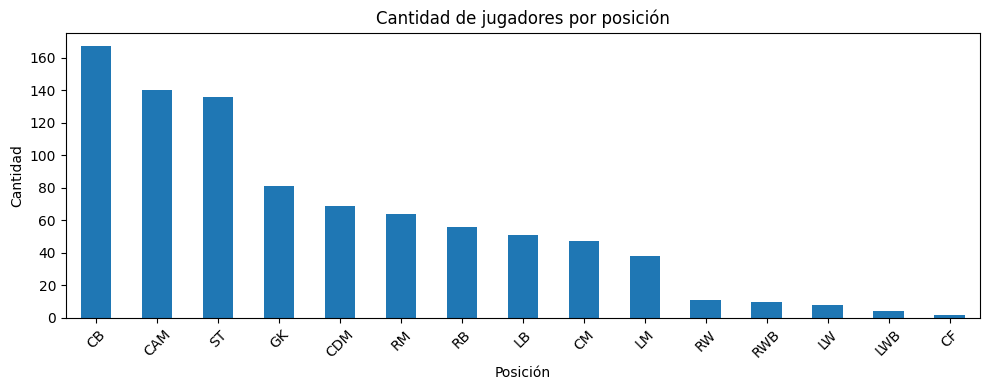

In [ ]:
import matplotlib.pyplot as plt

df_named["best_position"].value_counts().plot(kind="bar", figsize=(10, 4))
plt.title("Cantidad de jugadores por posición")
plt.ylabel("Cantidad")
plt.xlabel("Posición")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Gráfico de barras: ataque promedio por posición

Combinamos `.groupby()` con `.mean()` y luego graficamos el resultado.


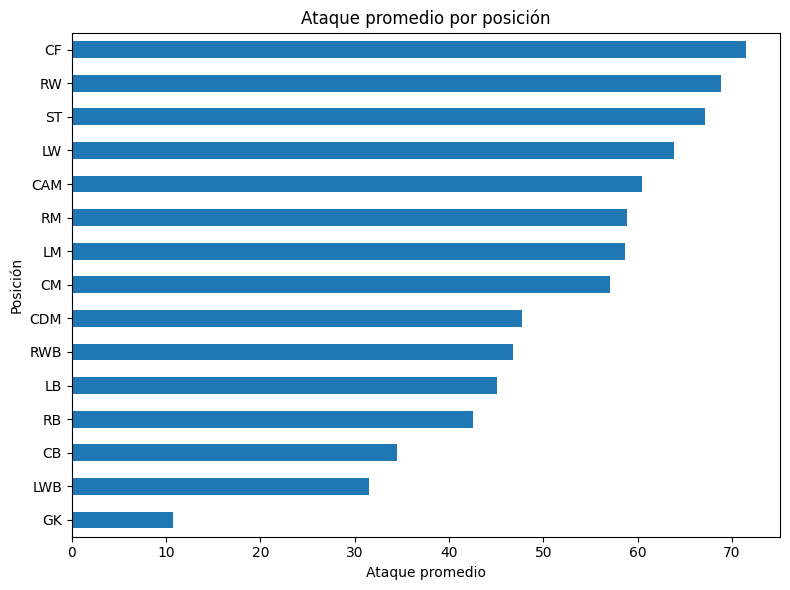

In [ ]:
df_named.groupby("best_position")["attacking_finishing"].mean().sort_values().plot(kind="barh", figsize=(8, 6))
plt.title("Ataque promedio por posición")
plt.xlabel("Ataque promedio")
plt.ylabel("Posición")
plt.tight_layout()
plt.show()

### Gráfico de dispersión: velocidad vs. ataque

El gráfico de dispersión permite visualizar relaciones entre dos variables numéricas.


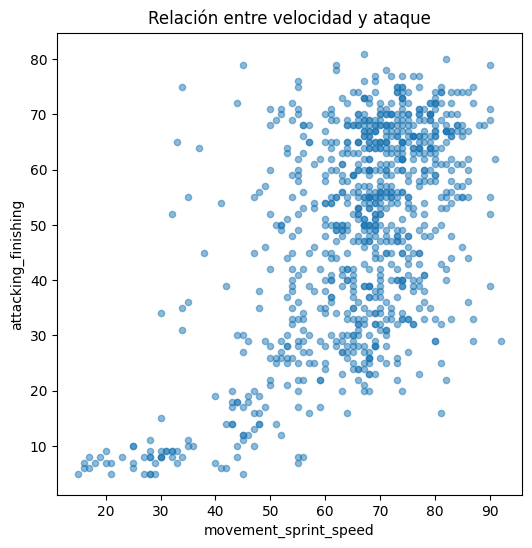

In [ ]:
df_named.plot(kind="scatter", x="movement_sprint_speed", y="attacking_finishing", alpha=0.5, figsize=(6, 6))
plt.title("Relación entre velocidad y ataque")
plt.show()

### Histograma: distribución de velocidad

Un histograma muestra cómo se distribuye una variable continua (como `movement_sprint_speed`) en intervalos.


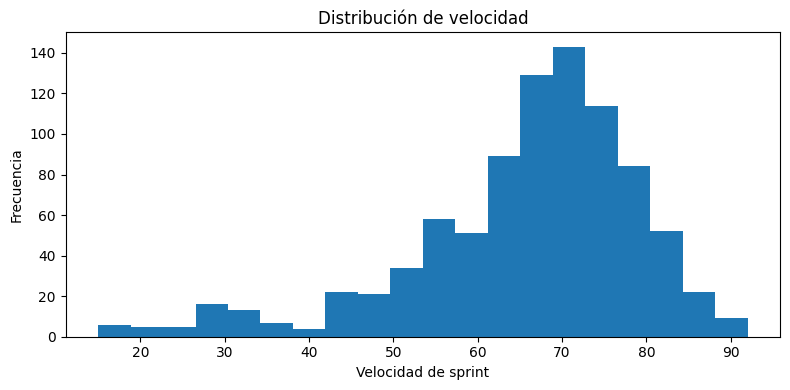

In [ ]:
df_named["movement_sprint_speed"].plot(kind="hist", bins=20, figsize=(8, 4))
plt.title("Distribución de velocidad")
plt.xlabel("Velocidad de sprint")
plt.ylabel("Frecuencia")
plt.tight_layout()
plt.show()

### Gráfico de líneas: evolución del ataque promedio por año de incorporación

Para analizar tendencias a lo largo del tiempo (o etapas), podemos usar un **gráfico de líneas**. En este caso, calculamos el **ataque promedio** por **año de incorporación al club** y lo graficamos.


In [ ]:
def texto_a_entero(texto: str) -> int:
    """Convierte a entero un texto que representa un número.

    Devuelve 0 si el texto no es convertible, para poder filtrar después.
    """
    try:
        return int(texto)
    except (TypeError, ValueError):
        return 0


df_named["anio_ingreso"] = df_named["club_joined_date"].apply(lambda x: str(x).split("-")[0])
df_named["anio_ingreso"] = df_named["anio_ingreso"].apply(texto_a_entero)

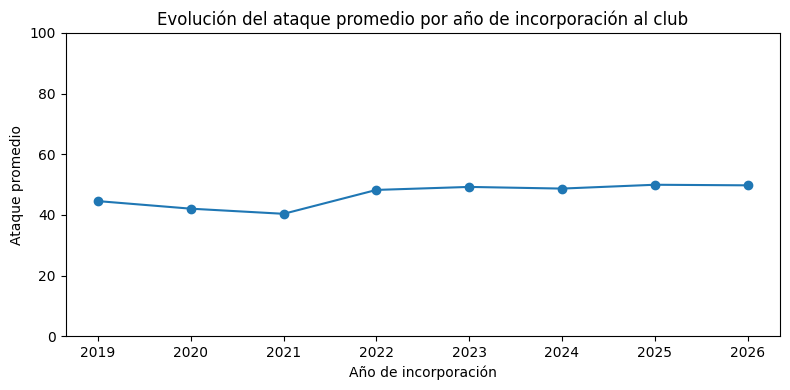

In [ ]:
import matplotlib.pyplot as plt

attack_por_anio = df_named.query("anio_ingreso >= 2019").groupby("anio_ingreso")["attacking_finishing"].mean()

attack_por_anio.plot(kind="line", marker="o", figsize=(8, 4))
plt.title("Evolución del ataque promedio por año de incorporación al club")
plt.xlabel("Año de incorporación")
plt.ylabel("Ataque promedio")
plt.ylim(0, 100)
plt.xticks(attack_por_anio.index)  # asegura que se vean todos los años
plt.tight_layout()
plt.show()




Este tipo de gráfico permite identificar **tendencias** (subas/bajas) entre años y detectar **rupturas** o **cambios** marcados en el comportamiento del atributo.


### Diagrama de caja (`boxplot`)

Un boxplot resume la distribución de una variable numérica a través de:

- el cuartil 1 (Q1)
- la mediana (Q2)
- el cuartil 3 (Q3)
- los valores máximos y mínimos sin considerar outliers
- posibles valores atípicos (*outliers*)

Es útil para:

- detectar asimetrías
- comparar rangos entre grupos
- identificar valores extremos

En pandas podemos usar:

```python
df.boxplot(column="columna", by="columna_categórica")



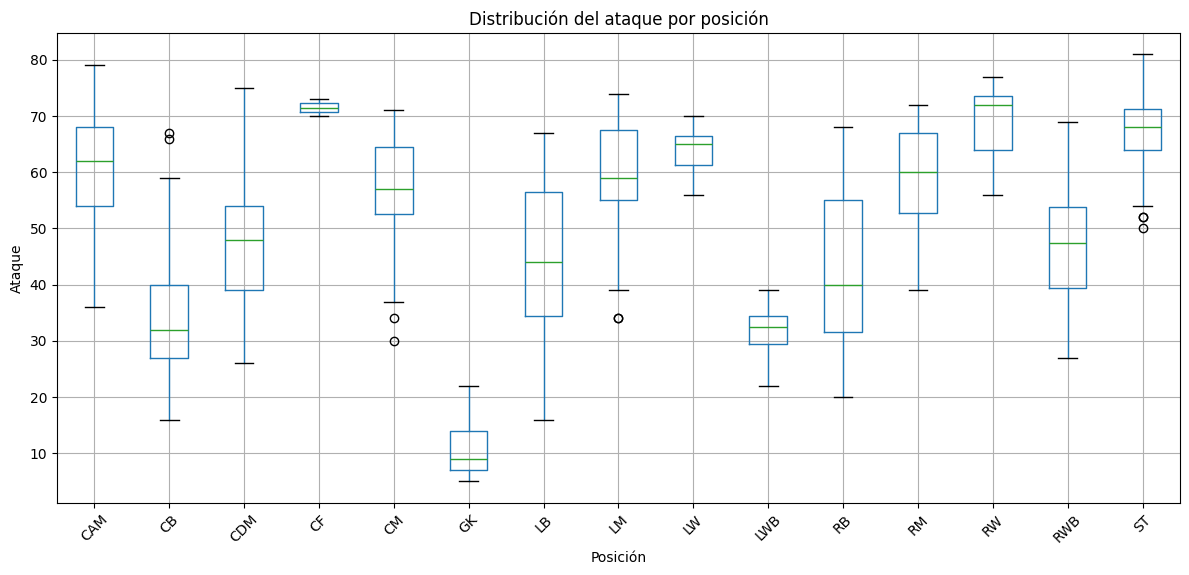

In [ ]:
df_named.boxplot(column="attacking_finishing", by="best_position", figsize=(12, 6), rot=45)
plt.title("Distribución del ataque por posición")
plt.suptitle("")  # elimina título automático redundante
plt.xlabel("Posición")
plt.ylabel("Ataque")
plt.tight_layout()
plt.show()

Este gráfico nos permite ver rápidamente:

- Qué posiciones tienen mayor variabilidad en ataque
- Dónde se ubican las medianas de cada grupo
- Si hay valores atípicos que sobresalen

Este tipo de visualización es especialmente útil cuando trabajamos con **agrupamientos categóricos** y variables numéricas.


# Sección 8: Pipelines en pandas

Después de conocer las operaciones básicas —selección, filtrado, creación de columnas, agrupamiento, ordenamiento— podemos combinarlas de forma fluida usando **pipelines**.

El pipelining consiste en **encadenar operaciones** usando el operador `.` de forma progresiva, sin necesidad de crear variables intermedias.

Esto mejora:

- la legibilidad del código
- la trazabilidad del análisis
- la reproducibilidad de los pasos

En lugar de hacer:

```python
filtro = df[df["movement_sprint_speed"] > 80]
nueva = filtro.assign(velocidad_norm = filtro["movement_sprint_speed"] / filtro["movement_sprint_speed"].max())
agrupado = nueva.groupby("best_position")["velocidad_norm"].mean()


In [ ]:
df[df["movement_sprint_speed"] > 80] \
  .assign(velocidad_norm = lambda d: d["movement_sprint_speed"] / d["movement_sprint_speed"].max()) \
  .groupby("best_position")["velocidad_norm"].mean()

,velocidad_norm
best_position,
CAM,0.914251
CB,0.904348
CDM,0.880435
LB,0.911232
LM,0.917120
LW,0.902174
LWB,0.891304
RB,0.925725
RM,0.909091


O mejor aún, usando .query() y .pipe():

In [ ]:
(
    df_named
    .query("movement_sprint_speed > 80")
    .assign(
        velocidad_norm = lambda d: d["movement_sprint_speed"] / d["movement_sprint_speed"].max(),
        atk_def_ratio = lambda d: d["attacking_finishing"] / d["defending_standing_tackle"]
    )
    .groupby("best_position")
    .agg(
        ataque_promedio = ("attacking_finishing", "mean"),
        velocidad_norm_prom = ("velocidad_norm", "mean"),
        relacion_atk_def = ("atk_def_ratio", "mean"),
        cantidad = ("best_position", "count")
    )
    .sort_values(by="ataque_promedio", ascending=False)
    .reset_index()
)

,best_position,ataque_promedio,velocidad_norm_prom,relacion_atk_def,cantidad
0,ST,69.538462,0.913880,2.442939,13
1,CAM,69.444444,0.914251,1.527608,9
2,LW,66.000000,0.902174,1.885714,1
3,RW,65.000000,0.902174,2.091667,2
4,LM,63.875000,0.917120,1.687456,8
5,RM,62.863636,0.909091,1.941928,22
6,RWB,60.333333,0.956522,0.885170,3
7,CDM,50.000000,0.880435,0.781250,1
8,RB,47.916667,0.925725,0.714025,12
9,LB,43.333333,0.911232,0.636938,6


Este pipeline realiza:

1. **Filtrado** → solo jugadores con velocidad mayor a 80
2. **Asignación de columnas**:
    - `velocidad_norm`: velocidad normalizada
    - `atk_def_ratio`: relación ataque/defensa
3. **Agrupamiento por posición**
4. **Agregaciones múltiples**
5. **Ordenamiento descendente por ataque promedio**
6. **Reseteo de índice** para tener una tabla lista para mostrar o exportar

Esto resume muchas operaciones que ya vimos, en un flujo claro y ordenado.


### ¿Qué es `.pipe()` en pandas?

El método `.pipe()` permite insertar funciones **externas o personalizadas** dentro de un pipeline, sin interrumpir el flujo de transformaciones.

Esto es útil cuando:

- Queremos aplicar una función definida por nosotros a un DataFrame
- Esa función toma el DataFrame como primer argumento
- Queremos mantener el estilo encadenado y limpio

#### Sintaxis:

```python
df.pipe(funcion, *args, **kwargs)


In [ ]:
def seleccionar_y_ordenar(df):
    return df[["best_position", "attacking_finishing", "defending_standing_tackle"]].sort_values(by="attacking_finishing", ascending=False)

df_named.pipe(seleccionar_y_ordenar).head()

,best_position,attacking_finishing,defending_standing_tackle
long_name,,,
Adrián Martínez,ST,81,44
Nicolás Fernández,ST,80,39
Leandro Díaz,ST,79,23
Sebastián Villa,CAM,79,27
Franco Vázquez,CAM,79,59


Podemos usar `.pipe()` para insertar funciones intermedias dentro de un pipeline largo. Esto nos permite encapsular lógicas que no se expresan bien con métodos encadenados.

Ejemplo: función que filtra tipos con más de N observaciones.


In [ ]:
def filtrar_grupos_con_minimo(df, min_cantidad=5):
    conteos = df["best_position"].value_counts()
    posiciones_validas = conteos[conteos >= min_cantidad].index
    return df[df["best_position"].isin(posiciones_validas)]

(
    df_named
    .pipe(filtrar_grupos_con_minimo, min_cantidad=10)
    .groupby("best_position")
    .agg(
        ataque_promedio = ("attacking_finishing", "mean"),
        velocidad_promedio = ("movement_sprint_speed", "mean"),
        cantidad = ("best_position", "count")
    )
    .sort_values(by="ataque_promedio", ascending=False)
    .reset_index()
)

,best_position,ataque_promedio,velocidad_promedio,cantidad
0,RW,68.818182,77.818182,11
1,ST,67.176471,67.779412,136
2,CAM,60.471429,69.778571,140
3,RM,58.875000,75.859375,64
4,LM,58.684211,75.368421,38
5,CM,57.085106,65.191489,47
6,CDM,47.681159,62.927536,69
7,RWB,46.800000,77.900000,10
8,LB,45.039216,74.215686,51
9,RB,42.553571,73.785714,56


### Conclusión

El pipelining con pandas es una forma natural y poderosa de organizar transformaciones complejas:

- Hace el código más legible y mantenible
- Elimina la necesidad de múltiples variables intermedias
- Refleja la lógica del análisis paso a paso

Este estilo es especialmente útil cuando trabajamos con notebooks o scripts que sirven como documentación del análisis.

**Regla de oro**: si tus pasos pueden expresarse como transformaciones secuenciales, es un buen momento para usar un pipeline.
